In [1]:
# imports and config
import numpy as np
import pandas as pd
from pathlib import Path
import scipy.stats
from tqdm import tqdm
from plotnine import *


In [2]:
dir = Path('account_example_n20000')


In [3]:

config = pd.read_csv(dir / 'config.csv')
scan_perf = pd.read_csv(dir / 'scan_perf.csv')


In [4]:
study_rate = float(config.loc[0, 'study_rate'])
incoming_int_columns = (
    'presumed_indications',
    'n_true_positive', 'n_false_positive',
    'n_false_negative', 'n_true_negative',
    'n compromised | no intervention',
    'n compromised | intervention',
    'n at risk | intervention',
    'n at risk | no intervention',
    'n_at_risk',
)
for v in incoming_int_columns:
    scan_perf[v] = scan_perf[v].astype(int)

In [5]:
# shared formatting
value_formats = {
    'n_true_positive': '{:0.1f}',
    'n_false_positive': '{:0.1f}',
    'n_false_negative': '{:0.1f}',
    'n_true_negative': '{:0.1f}',
    'precision': '{:.1%}',
    'recall': '{:.1%}',
    'E[indications]': '{:0.1f}',
    'sd[indications]': '{:0.1f}', 
    'cost with intervention': "${:,.2f}", 
    'scan value': "${:,.2f}",
    'scan_cost': "${:,.2f}",
    'intervention_cost': "${:,.2f}",
    'intervention_effectiveness': '{:.0%}',
    'expected_loss': "${:,.2f}",
    'E[compromises | no action]': '{:0.1f}', 
    'E[compromises | intervened]': '{:0.1f}',
    'E[at risk | no action]': '{:0.1f}', 
    'E[at risk | intervened]': '{:0.1f}',
    'intervention cost': "${:,.2f}", 
    'post intervention losses': "${:,.2f}", 
    'cost with intervention': "${:,.2f}",
    'no intervention losses': "${:,.2f}",
    'scan cost': "${:,.2f}",
    'return on spend': '{:.0%}', 
    'at risk rate outside selection': '{:.3%}', 
    'attacker_coverage': '{:.1%}',
    'presumed_at_risk_rate': "{:0.2%}",
    'calibration_possible_positives': '{:.0f}', 
    'calibration_true_positives': '{:.0f}',
    'calibration_possible_negatives': '{:.0f}', 
    'calibration_true_negatives': '{:.0f}',
    'n_accounts': '{:.0f}', 
    'study_rate': '{:0.2%}',
    'anticipated at risk': '{:0.1f}',
    'anticipated attacks': '{:0.1f}',
    'n compromised | no intervention': '{:0.1f}',
    'n compromised | intervention': '{:0.1f}',
    'n_at_risk': '{:0.1f}',
    'n_at_risk | no intervention': '{:0.1f}',
    'n at risk | intervention': '{:0.1f}',
    'attacker_coverage': '{:0.1%}',
    'last_year_loss': "${:,.2f}",
    'sd_loss': "${:,.2f}",
    "n at risk | no intervention": '{:0.1f}',
    'modeled_sensitivity': '{:0.1%}',
    'modeled_specificity': '{:0.1%}',
}
index_formats = lambda x: f"{x:0.2%}" if isinstance(x, float) else str(x)

In [6]:
# get the matching rates
group_vars = ['presumed_at_risk_rate', 'presumed_indications']
rate_frame = scan_perf[group_vars + ['E[indications]']].groupby(group_vars).mean()
rate_frame = rate_frame.reset_index(drop=False, inplace=False)
rate_frame['diff'] = np.abs(rate_frame['presumed_indications'] - rate_frame['E[indications]'])
rate_frame['min'] = rate_frame.groupby(['presumed_at_risk_rate']).transform('min')['diff']
rate_frame = rate_frame.loc[rate_frame['diff'] <= rate_frame['min'], :]
rate_frame = rate_frame[group_vars].groupby(group_vars).first().reset_index(drop=False, inplace=False)
rate_frame.style.format(value_formats).hide(axis="index")

presumed_at_risk_rate,presumed_indications
1.00%,1300
1.50%,1400
2.00%,1400
2.50%,1500
3.00%,1600


In [7]:
ind_frame = (
    scan_perf
        .groupby(group_vars)
        [['E[indications]', 'modeled_sensitivity', 'modeled_specificity']]
        .mean()
)
(
    ind_frame
        .style
        .format_index(index_formats)
        .format(value_formats)
)

In [8]:
target_indications_value = int(
    rate_frame.loc[rate_frame['presumed_at_risk_rate'] == study_rate, 'presumed_indications'].values[0])

target_indications_value

1400

In [9]:
scan_perf.loc[
    (scan_perf['presumed_at_risk_rate'] == study_rate)
    & (scan_perf['presumed_indications'] == target_indications_value),
    :].head().style.format({k: v for k, v in value_formats.items() if k not in incoming_int_columns}).hide(axis="index")

modeled_sensitivity,modeled_specificity,n_at_risk,n_safe,presumed_at_risk_rate,presumed_indications,n_true_positive,n_false_positive,n_false_negative,n_true_negative,attacker_coverage,n at risk | intervention,n at risk | no intervention,n compromised | no intervention,n compromised | intervention,no intervention losses,post intervention losses,E[indications],var[indications]
62.2%,94.2%,402,19598,2.00%,1400,254,1146,148,18452,12.8%,199,402,48,21,"$630,665.44","$237,952.38",1430.8,1362.337278
86.9%,94.8%,441,19559,2.00%,1400,374,1026,67,18533,13.7%,137,441,64,23,"$802,939.90","$294,656.38",1430.8,1362.337278
65.9%,94.0%,405,19595,2.00%,1400,257,1143,148,18452,10.0%,196,405,42,17,"$503,754.27","$209,724.51",1430.8,1362.337278
79.7%,94.5%,407,19593,2.00%,1400,331,1069,76,18524,9.9%,130,407,52,19,"$566,125.16","$227,331.84",1430.8,1362.337278
67.0%,94.2%,411,19589,2.00%,1400,272,1128,139,18461,15.9%,197,411,73,36,"$887,520.55","$409,437.90",1430.8,1362.337278


In [10]:
# derive usual columns
scan_perf['precision'] = scan_perf['n_true_positive'] / (
    scan_perf['n_true_positive'] + scan_perf['n_false_positive'])
scan_perf['recall'] = scan_perf['n_true_positive'] / (
    scan_perf['n_true_positive'] + scan_perf['n_false_negative'])


In [11]:
target_row_colorer = lambda row: (
    ["background-color: lightgreen" if row.name == (study_rate, target_indications_value) else ""] * len(row)
    )
rx_targets = tuple([(np.float64(k), np.int64(v)) for k, v in zip(rate_frame['presumed_at_risk_rate'], rate_frame['presumed_indications'])])
target_rows_colorer = lambda row: (
    ["background-color: lightblue" if row.name in rx_targets else ""]
    + ["background-color: lightgreen" if row.name == (study_rate, target_indications_value) else ""] * (len(row) - 1)
    )

In [12]:
config.T.style.hide(axis="columns")

calibration_possible_positives,10
calibration_true_positives,8
calibration_possible_negatives,50
calibration_true_negatives,48
last_year_loss,541989.510000
n_compromised_last_year,45
n_accounts_last_year,19000
n_accounts,20000
study_rate,0.020000
scan_cost,5.000000
intervention_cost,100.000000


In [13]:
config[[
    'n_accounts_last_year', 'n_compromised_last_year', 'last_year_loss',
    'n_accounts', 'expected_loss', 'sd_loss',
]].style.format(value_formats).hide(axis="index")

n_accounts_last_year,n_compromised_last_year,last_year_loss,n_accounts,expected_loss,sd_loss
19000,45,"$541,989.51",20000,"$12,000.00","$4,000.00"


In [14]:
config[[
    'calibration_possible_positives', 'calibration_true_positives', 'calibration_possible_negatives', 'calibration_true_negatives',
    'scan_cost',
]].style.format(value_formats).hide(axis="index")

calibration_possible_positives,calibration_true_positives,calibration_possible_negatives,calibration_true_negatives,scan_cost
10,8,50,48,$5.00


In [15]:
config[[
    'intervention_cost', 'intervention_effectiveness',
]].style.format(value_formats).hide(axis="index")

intervention_cost,intervention_effectiveness
$100.00,80%


In [16]:
pd.DataFrame({
    'risk rate': ['????'],
    'number of indications': ['????'],
}).style.hide(axis="index")

risk rate,number of indications
????,????


In [17]:
target_scan = scan_perf.loc[
    (scan_perf['presumed_at_risk_rate'] == study_rate)
    & (scan_perf['presumed_indications'] == target_indications_value),
               :].reset_index(drop=True, inplace=False)

def color_last_row_by_column(s):
    if s.name == 'what is observed':
        # Map column names to colors
        cm_colors = {
            'indicated': 'background-color: orange', 
            'not indicated': 'background-color: lightblue',
            }
        return [cm_colors.get(col, '') for col in s.index]
    return [''] * len(s)

for i in range(5):
    cmi = pd.DataFrame({
        'indicated': [
            target_scan.loc[i, 'n_true_positive'], 
            target_scan.loc[i, 'n_false_positive'],
            target_scan.loc[i, 'n_true_positive'] + target_scan.loc[i, 'n_false_positive'],
            ],
        'not indicated': [
            target_scan.loc[i, 'n_false_negative'], 
            target_scan.loc[i, 'n_true_negative'],
            target_scan.loc[i, 'n_false_negative'] + target_scan.loc[i, 'n_true_negative'],
            ],
        },
        index=['vulnerable', 'not vulnerable', 'what is observed'],                       
    ).style.apply(color_last_row_by_column, axis=1).map_index(
            lambda v: 'font-weight: bold' if v == 'what is observed' else '', 
            axis=0
        )
    display(cmi)

,indicated,not indicated
vulnerable,254,148
not vulnerable,1146,18452
what is observed,1400,18600


,indicated,not indicated
vulnerable,374,67
not vulnerable,1026,18533
what is observed,1400,18600


,indicated,not indicated
vulnerable,257,148
not vulnerable,1143,18452
what is observed,1400,18600


,indicated,not indicated
vulnerable,331,76
not vulnerable,1069,18524
what is observed,1400,18600


,indicated,not indicated
vulnerable,272,139
not vulnerable,1128,18461
what is observed,1400,18600


In [18]:
measure_vars = [
    'E[indications]',
    'n_true_positive', 'n_false_negative',
    'n_false_positive', 'n_true_negative',
    'precision', 'recall',
    'n compromised | intervention', 'n compromised | no intervention', 
    ]
stat_table = (
    scan_perf[group_vars + measure_vars]
    .groupby(group_vars)
    .mean()
)


In [19]:
# get the single row we want
summary_row = stat_table.loc[[(study_rate, target_indications_value)],:]
(
    summary_row
        .style
        .format(value_formats)
        .format_index(index_formats)
        .apply(target_row_colorer, axis=1)
)


,,E[indications],n_true_positive,n_false_negative,n_false_positive,n_true_negative,precision,recall,n compromised | intervention,n compromised | no intervention
presumed_at_risk_rate,presumed_indications,,,,,,,,,
2.00%,1400,1430.8,303.3,98.1,1096.7,18501.9,21.7%,75.5%,19.4,49.0


In [20]:
(
    stat_table
        .style
        .format(value_formats)
        .format_index(index_formats)
)

In [21]:
(
    stat_table
        .style
        .format(value_formats)
        .format_index(index_formats)
        .apply(target_rows_colorer, axis=1)
)

In [22]:
(
    stat_table.loc[[(k in rx_targets) for k in stat_table.index], :]
        .style
        .format(value_formats)
        .format_index(index_formats)
        .apply(target_row_colorer, axis=1)
)

,,E[indications],n_true_positive,n_false_negative,n_false_positive,n_true_negative,precision,recall,n compromised | intervention,n compromised | no intervention
presumed_at_risk_rate,presumed_indications,,,,,,,,,
1.00%,1300,1292.3,149.9,49.3,1150.1,18650.7,11.5%,75.3%,19.2,48.3
1.50%,1400,1361.5,226.5,73.5,1173.5,18526.5,16.2%,75.5%,19.1,48.3
2.00%,1400,1430.8,303.3,98.1,1096.7,18501.9,21.7%,75.5%,19.4,49.0
2.50%,1500,1500.0,378.7,121.3,1121.3,18378.7,25.2%,75.8%,19.3,48.7
3.00%,1600,1569.2,457.1,143.5,1142.9,18256.5,28.6%,76.1%,18.9,48.4


In [23]:
scan_cost = config.loc[0, 'scan_cost']
intervention_cost = config.loc[0, 'intervention_cost']


In [24]:

# compute cost in pieces
scan_perf['scan cost'] = (
    scan_perf['n_true_positive'] 
    + scan_perf['n_false_negative'] 
    + scan_perf['n_false_positive'] 
    + scan_perf['n_true_negative'] 
) * scan_cost
scan_perf['intervention cost'] = (
    scan_perf['n_true_positive']
    + scan_perf['n_false_positive']
) * intervention_cost
scan_perf['cost with intervention'] = scan_perf['scan cost'] + scan_perf['intervention cost'] + scan_perf['post intervention losses']
scan_perf['scan value'] = scan_perf['no intervention losses'] - scan_perf['cost with intervention']
scan_perf['return on spend'] = scan_perf['scan value'] / (scan_perf['scan cost'] + scan_perf['intervention cost'])


In [25]:
measure_vars = [
    'E[indications]',
    'n at risk | intervention', 'n at risk | no intervention', 
    'attacker_coverage',
    'n compromised | intervention',  'n compromised | no intervention', 
    ]
z_table = (
    scan_perf[group_vars + measure_vars]
    .groupby(group_vars)
    .mean()
)
z_table

E[indications]  \
presumed_at_risk_rate presumed_indications                   
0.010                 1200                     1292.307692   
                      1300                     1292.307692   
                      1400                     1292.307692   
0.015                 1300                     1361.538462   
                      1400                     1361.538462   
                      1500                     1361.538462   
0.020                 1300                     1430.769231   
                      1400                     1430.769231   
                      1500                     1430.769231   
0.025                 1400                     1500.000000   
                      1500                     1500.000000   
                      1600                     1500.000000   
0.030                 1500                     1569.230769   
                      1600                     1569.230769   
                      1700                     1569.230769   

                                            n at risk | intervention  \
presumed_at_risk_rate presumed_indications                             
0.010                 1200                                    79.316   
                      1300                                    79.334   
                      1400                                    78.180   
0.015                 1300                                   119.766   
                      1400                                   118.974   
                      1500                                   119.640   
0.020                 1300                                   158.283   
                      1400                                   158.345   
                      1500                                   157.861   
0.025                 1400                                   199.312   
                      1500                                   197.183   
                      1600                                   197.065   
0.030                 1500                                   235.421   
                      1600                                   235.129   
                      1700                                   236.184   

                                            n at risk | no intervention  \
presumed_at_risk_rate presumed_indications                                
0.010                 1200                                      199.878   
                      1300                                      199.181   
                      1400                                      199.548   
0.015                 1300                                      299.921   
                      1400                                      300.056   
                      1500                                      300.120   
0.020                 1300                                      400.992   
                      1400                                      401.424   
                      1500                                      399.841   
0.025                 1400                                      499.889   
                      1500                                      499.951   
                      1600                                      499.907   
0.030                 1500                                      599.897   
                      1600                                      600.615   
                      1700                                      602.095   

                                            attacker_coverage  \
presumed_at_risk_rate presumed_indications                      
0.010                 1200                           0.241792   
                      1300                           0.242379   
                      1400                           0.241719   
0.015                 1300                           0.162279   
                      1400                           0.161411   
                      1500       

In [26]:

(
z_table
    .loc[[(study_rate, target_indications_value)],:]
    .style
    .format(value_formats)
    .format_index(index_formats)
    .apply(target_row_colorer, axis=1)
)

,,E[indications],n at risk | intervention,n at risk | no intervention,attacker_coverage,n compromised | intervention,n compromised | no intervention
presumed_at_risk_rate,presumed_indications,,,,,,
2.00%,1400,1430.8,158.3,401.4,12.2%,19.4,49.0


In [27]:

(
z_table
    .loc[[(k in rx_targets) for k in z_table.index], :]
    .style
    .format(value_formats)
    .format_index(index_formats)
    .apply(target_row_colorer, axis=1)
)


,,E[indications],n at risk | intervention,n at risk | no intervention,attacker_coverage,n compromised | intervention,n compromised | no intervention
presumed_at_risk_rate,presumed_indications,,,,,,
1.00%,1300,1292.3,79.3,199.2,24.2%,19.2,48.3
1.50%,1400,1361.5,119.0,300.1,16.1%,19.1,48.3
2.00%,1400,1430.8,158.3,401.4,12.2%,19.4,49.0
2.50%,1500,1500.0,197.2,500.0,9.7%,19.3,48.7
3.00%,1600,1569.2,235.1,600.6,8.1%,18.9,48.4


In [28]:

(
z_table
    .loc[[(k in rx_targets) for k in z_table.index], :]
    .style
    .format(value_formats)
    .format_index(index_formats)
    .apply(target_row_colorer, axis=1)
)

,,E[indications],n at risk | intervention,n at risk | no intervention,attacker_coverage,n compromised | intervention,n compromised | no intervention
presumed_at_risk_rate,presumed_indications,,,,,,
1.00%,1300,1292.3,79.3,199.2,24.2%,19.2,48.3
1.50%,1400,1361.5,119.0,300.1,16.1%,19.1,48.3
2.00%,1400,1430.8,158.3,401.4,12.2%,19.4,49.0
2.50%,1500,1500.0,197.2,500.0,9.7%,19.3,48.7
3.00%,1600,1569.2,235.1,600.6,8.1%,18.9,48.4


In [29]:

(
z_table
    .style
    .format(value_formats)
    .format_index(index_formats)
    .apply(target_rows_colorer, axis=1)
)

In [30]:

measure_vars = [
    'E[indications]',
    'no intervention losses', 
    'intervention cost', 
    'post intervention losses',
    'cost with intervention', 'scan value',
    'return on spend',
    # 'n compromised | no intervention', 'n compromised | intervention', 
    # 'n_at_risk', 'n at risk | intervention',
    ]
g_table = (
    scan_perf[group_vars + measure_vars]
    .groupby(group_vars)
    .mean()
)
g_table['recommendation'] = "scan" 
g_table.loc[
    g_table['scan value'] <= 0, 
    'recommendation'] = "don't scan"

In [31]:

(
g_table
    .loc[[(study_rate, target_indications_value)],:]
    .style
    .format(value_formats)
    .format_index(index_formats).map(
            lambda value: "color: red" if value < 0 else "",
            subset=['scan value', 'return on spend'])
    .apply(target_row_colorer, axis=1)
)

,,E[indications],no intervention losses,intervention cost,post intervention losses,cost with intervention,scan value,return on spend,recommendation
presumed_at_risk_rate,presumed_indications,,,,,,,,
2.00%,1400,1430.8,"$588,219.60","$140,000.00","$233,171.83","$473,171.83","$115,047.76",48%,scan


In [32]:
(
   g_table.loc[[(k in rx_targets) for k in g_table.index], :]
        .style
        .format(value_formats)
        .format_index(index_formats).map(
                lambda value: "color: red" if value < 0 else "",
                subset=['scan value', 'return on spend'])
        .apply(target_row_colorer, axis=1)
)

,,E[indications],no intervention losses,intervention cost,post intervention losses,cost with intervention,scan value,return on spend,recommendation
presumed_at_risk_rate,presumed_indications,,,,,,,,
1.00%,1300,1292.3,"$579,765.82","$130,000.00","$229,222.05","$459,222.05","$120,543.77",52%,scan
1.50%,1400,1361.5,"$579,463.44","$140,000.00","$229,825.02","$469,825.02","$109,638.43",46%,scan
2.00%,1400,1430.8,"$588,219.60","$140,000.00","$233,171.83","$473,171.83","$115,047.76",48%,scan
2.50%,1500,1500.0,"$583,604.87","$150,000.00","$232,181.56","$482,181.56","$101,423.31",41%,scan
3.00%,1600,1569.2,"$581,346.96","$160,000.00","$225,503.41","$485,503.41","$95,843.55",37%,scan


In [33]:
(
   g_table
        .style
        .format(value_formats)
        .format_index(index_formats).map(
                lambda value: "color: red" if value < 0 else "",
                subset=['scan value', 'return on spend'])
        .apply(target_rows_colorer, axis=1)
)

In [34]:
(
   g_table
        .style
        .format(value_formats)
        .format_index(index_formats).map(
                lambda value: "color: red" if value < 0 else "",
                subset=['scan value', 'return on spend'])
)

In [35]:
study_frame = scan_perf.loc[
    (scan_perf['presumed_at_risk_rate'] == study_rate) 
    & (scan_perf['presumed_indications'] == target_indications_value), 
    ['scan value']
    ]


In [36]:
qs = np.quantile(study_frame['scan value'], (0.25, 0.5, 0.75))

qs

array([ 40576.88771021, 110309.87696613, 178506.8511237 ])

In [37]:
sd = np.std(study_frame['scan value'])

sd

np.float64(108401.77933992326)

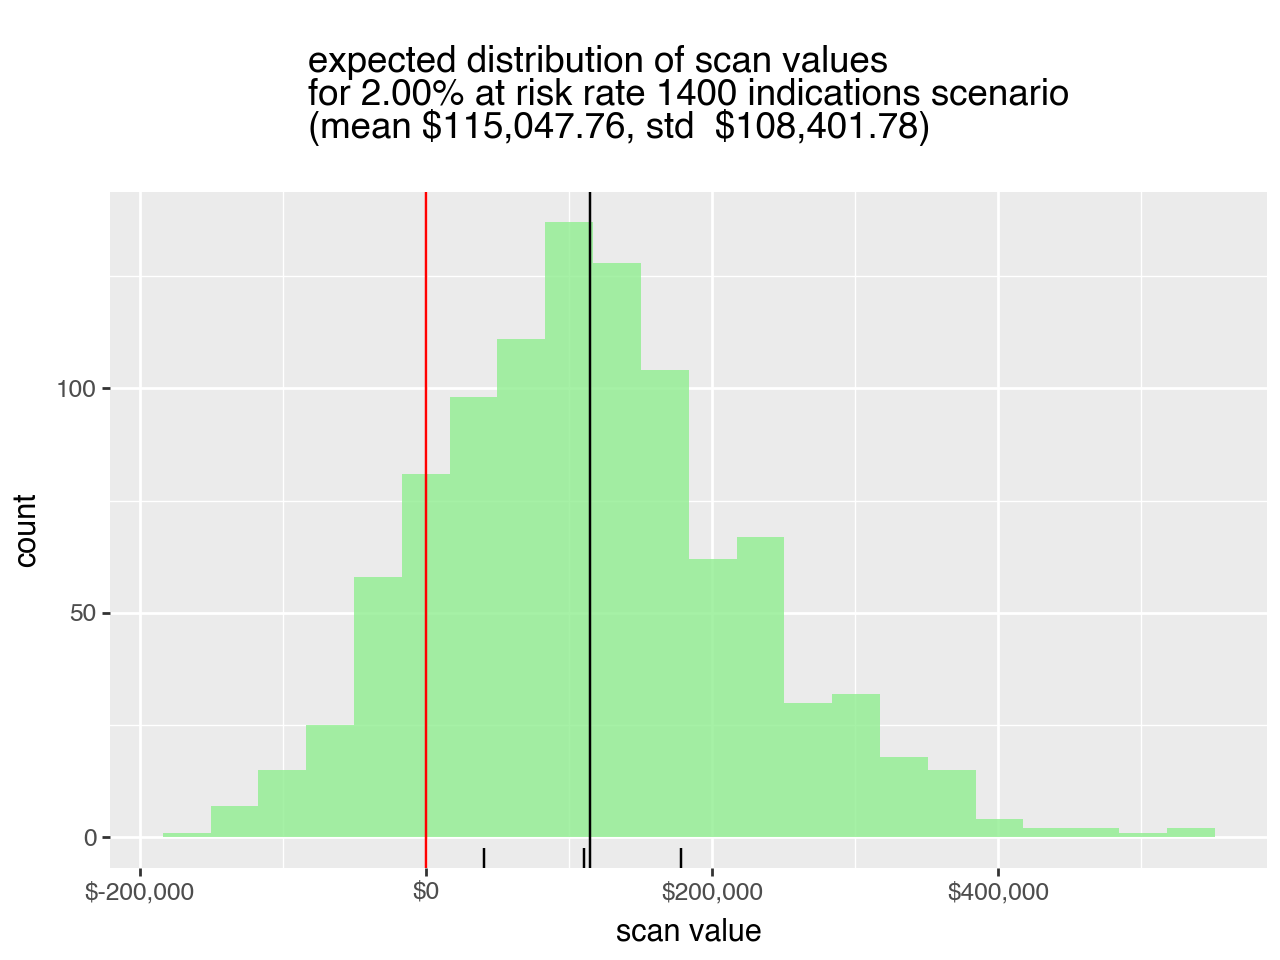

In [45]:
(
    ggplot(
        data=study_frame,
        mapping=aes(x='scan value'))
        + geom_histogram(fill='lightgreen', alpha=0.8, color=None, bins=22)
        + geom_vline(xintercept=0, color='red')
        + geom_vline(xintercept=np.mean(study_frame['scan value']))
        + geom_rug(data=pd.DataFrame({'scan value': qs}))
        + scale_x_continuous(labels=lambda xs: [f"${x:,.0f}" for x in xs])
        + ggtitle(f"""
expected distribution of scan values
for {study_rate:.2%} at risk rate {target_indications_value} indications scenario
(mean \${np.mean(study_frame['scan value']):,.2f}, std  \${sd:,.2f})
""")
)


In [39]:
float(np.mean(study_frame['scan value'] > 0))

0.86

In [40]:
float(np.min(study_frame['scan value']))

-172311.80652205506

In [41]:
float(np.mean(study_frame['scan value'] > -10000))

0.883

In [42]:
float(np.mean(study_frame['scan value'] > 10000))

0.833

In [43]:
float(np.mean(study_frame['scan value']))

115047.76420436932

In [44]:
float(np.std(study_frame['scan value']))

108401.77933992326